# STBP Ablation Studies

Two ablation studies for the Spatio-Temporal Bound Propagation paper:
1. **First-layer tightness propagation** — per-layer bound width comparison (IBP vs STBP)
2. **LJ sampling sensitivity** — vary N_samples with corrected analytical bounds

In [1]:
#!pip install ipython-autotime
%load_ext autotime 
#to measure cell execution time of all cells

time: 155 μs (started: 2026-03-26 14:21:07 +00:00)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
import numpy as np
import os
import sys
from pathlib import Path
import itertools
import torchvision.transforms.functional as TF

DEVICE = 'cuda:1' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')

PROJECT_ROOT = Path('/data/sv/temporal-nn-verification')
MNIST_DATASET_PATH = Path('/vol/bitbucket/svadakku/data/mnist/')
MODELS_PATH = PROJECT_ROOT / 'mnist_toy_example' / 'models'

input_frames = 10
resize_shape = (28, 28)
num_classes = 10
batch_size = 100


Using device: cuda
time: 4.4 s (started: 2026-03-26 14:21:07 +00:00)


In [3]:
# Dataset to convert MNIST into sequence of frames
class MNISTVideoDataset(Dataset):
    def __init__(self, root, train=True, transform=None, frames=input_frames, resize_shape=(10, 10)):
        self.mnist = datasets.MNIST(root=root, train=train, download=True, transform=transform)
        self.frames = frames  # Number of frames per video
        self.resize_shape = resize_shape  # Target image resolution
        self.rotation = itertools.cycle([0, 5, 10, 15, 20, 25, -25, -20, -15, -10])  # Rotate images for variety
        self.translate = itertools.cycle([(0,0), (0,1), (1,2), (2,3), (3,4), (4,5), (-4,-5), (-3,-4), (-3,-2), (-2,-1)])  # Translate images for variety
        self.transform = transforms.Compose([
            transforms.Resize(resize_shape),  # Resize to specified resolution
            transforms.ToTensor(),
            #transforms.Pad(padding=padding_size),

            transforms.Lambda(lambda img: TF.affine( 
                img, 
                angle=next(self.rotation),  # Rotate images
                translate=next(self.translate), # Translate images
                scale=1.0, 
                shear=0
            )), 
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        # Dataset length is based on MNIST size divided by frames to form videos
        return len(self.mnist) // self.frames

    def __getitem__(self, idx):
        # Collect `frames` consecutive MNIST images to form a video
        start_idx = idx * self.frames
        video_frames = []
        label = self.mnist[start_idx][1]  # Label is taken from the first frame in the sequence

        for i in range(self.frames):
            img, _ = self.mnist[start_idx]  # Ignore the label for other frames
            img = self.transform(img)  # Resize and transform each image
            video_frames.append(img.squeeze(0).numpy())  # Remove channel dim for stacking

        # Stack frames to shape (1, frames, H, W) for 3D CNN
        video_tensor = torch.tensor(np.stack(video_frames, axis=0), dtype=torch.float32).unsqueeze(0)
        return video_tensor, label

# Load training and validation datasets
train_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=True, frames=input_frames, resize_shape=resize_shape)
val_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=False, frames=input_frames, resize_shape=resize_shape)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

time: 1.13 s (started: 2026-03-26 14:21:12 +00:00)


In [4]:
class Simple3DCNN(nn.Module):
    def __init__(self):
        super(Simple3DCNN, self).__init__()
        self.conv1 = nn.Conv3d(in_channels=1, out_channels=2, kernel_size=2, stride=1, padding=0)
        self.conv2 = nn.Conv3d(in_channels=2, out_channels=4, kernel_size=2, stride=1, padding=1)
        self.conv3 = nn.Conv3d(in_channels=4, out_channels=8, kernel_size=2, stride=1, padding=1)
        dummy_input = torch.rand(1, 1, input_frames, *resize_shape)
        dummy_output = self._forward_conv_layers(dummy_input)
        flattened_size = dummy_output.view(1, -1).size(1)
        self.fc1 = nn.Linear(flattened_size, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def _forward_conv_layers(self, x):
        x = nn.ReLU()(self.conv1(x))
        x = nn.ReLU()(self.conv2(x))
        x = nn.ReLU()(self.conv3(x))
        return x

    def forward(self, x):
        x = self._forward_conv_layers(x)
        x = x.view(x.size(0), -1)
        x = nn.ReLU()(self.fc1(x))
        x = self.fc2(x)
        return x

model = Simple3DCNN()
model.load_state_dict(torch.load(MODELS_PATH / 'simple_3d_cnn.pth'))
model.eval()
model = model.to(DEVICE)
print('Model loaded successfully')


Model loaded successfully
time: 884 ms (started: 2026-03-26 14:21:13 +00:00)


## Core Functions

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from typing import Tuple, List, Dict, Optional, Union
from dataclasses import dataclass
import time
from tqdm import tqdm

@dataclass
class LayerBounds:
    lower: torch.Tensor
    upper: torch.Tensor
    @property
    def center(self): return (self.lower + self.upper) / 2
    @property
    def radius(self): return (self.upper - self.lower) / 2
    @property
    def width(self): return self.upper - self.lower
    def to(self, device): return LayerBounds(self.lower.to(device), self.upper.to(device))


time: 1.22 ms (started: 2026-03-26 14:21:14 +00:00)


In [6]:
def closed_form_conv3d_bounds(input_tensor, conv_layer, epsilon, shared_frames, device=DEVICE):
    """Compute EXACT bounds on Conv3D layer output using closed-form analytical solution."""
    if input_tensor.dim() == 4: input_tensor = input_tensor.unsqueeze(0)
    B, C, D, H, W = input_tensor.shape
    input_tensor = input_tensor.to(device)
    weights = conv_layer.weight.to(device)
    bias = conv_layer.bias.to(device) if conv_layer.bias is not None else None
    out_c, in_c, kd, kh, kw = weights.shape
    stride = conv_layer.stride[0] if isinstance(conv_layer.stride, tuple) else conv_layer.stride
    padding = conv_layer.padding[0] if isinstance(conv_layer.padding, tuple) else conv_layer.padding
    z_clean = F.conv3d(input_tensor, weights, bias, stride=stride, padding=padding)
    out_D = (D + 2 * padding - kd) // stride + 1
    all_shared = (len(shared_frames) == 1 and len(shared_frames[0]) == D)
    if all_shared:
        w_temporal_sum = weights.sum(dim=2)
        spatial_pert = torch.ones(B, in_c, H, W, device=device) * epsilon
        radius_2d = F.conv2d(spatial_pert, w_temporal_sum.abs(), bias=None, stride=stride, padding=padding)
        radius = radius_2d.unsqueeze(2).expand(-1, -1, out_D, -1, -1)
    else:
        radius = _compute_general_analytical_radius(input_tensor.shape, weights, epsilon, shared_frames, conv_layer, device)
    return LayerBounds(lower=z_clean - radius, upper=z_clean + radius)

def _compute_general_analytical_radius(input_shape, weights, epsilon, shared_frames, conv_layer, device):
    B, C, D, H, W = input_shape
    out_c, in_c, kd, kh, kw = weights.shape
    stride = conv_layer.stride[0] if isinstance(conv_layer.stride, tuple) else conv_layer.stride
    padding = conv_layer.padding[0] if isinstance(conv_layer.padding, tuple) else conv_layer.padding
    out_D = (D + 2 * padding - kd) // stride + 1
    out_H = (H + 2 * padding - kh) // stride + 1
    out_W = (W + 2 * padding - kw) // stride + 1
    radius = torch.zeros(B, out_c, out_D, out_H, out_W, device=device)
    for g_idx, group in enumerate(shared_frames):
        group_set = set(group)
        for od in range(out_D):
            kd_mask = torch.zeros(kd, device=device)
            for kd_idx in range(kd):
                input_d = od * stride + kd_idx - padding
                if 0 <= input_d < D and input_d in group_set:
                    kd_mask[kd_idx] = 1.0
            if kd_mask.sum() == 0: continue
            w_eff = (weights * kd_mask.view(1, 1, kd, 1, 1)).sum(dim=2)
            spatial_pert = torch.ones(B, in_c, H, W, device=device) * epsilon
            radius[:, :, od, :, :] += F.conv2d(spatial_pert, w_eff.abs(), bias=None, stride=stride, padding=padding)
    return radius


time: 2.38 ms (started: 2026-03-26 14:21:14 +00:00)


In [7]:
def Conv3D_IBP(lower_bound, upper_bound, conv_layer):
    x_mu, x_r = (upper_bound + lower_bound) / 2, (upper_bound - lower_bound) / 2
    W = conv_layer.weight
    z_L = F.conv3d(x_mu, W, conv_layer.bias, conv_layer.stride, conv_layer.padding) - F.conv3d(x_r, W.abs(), None, conv_layer.stride, conv_layer.padding)
    z_U = F.conv3d(x_mu, W, conv_layer.bias, conv_layer.stride, conv_layer.padding) + F.conv3d(x_r, W.abs(), None, conv_layer.stride, conv_layer.padding)
    return z_L, z_U

def Linear_IBP(lower_bound, upper_bound, fc_layer):
    x_mu, x_r = (upper_bound + lower_bound) / 2, (upper_bound - lower_bound) / 2
    W = fc_layer.weight
    z_L = F.linear(x_mu, W, fc_layer.bias) - F.linear(x_r, W.abs(), None)
    z_U = F.linear(x_mu, W, fc_layer.bias) + F.linear(x_r, W.abs(), None)
    return z_L, z_U

def ReLU_IBP(lower_bound, upper_bound):
    return F.relu(lower_bound), F.relu(upper_bound)

def interval_bound_propagation(model, input_tensor, epsilon=0.1, lower_input=None, upper_input=None):
    if lower_input is not None and upper_input is not None:
        lower_bounds, upper_bounds = lower_input, upper_input
    else:
        lower_bounds = input_tensor - epsilon
        upper_bounds = input_tensor + epsilon
    num_layers = len(list(model.children()))
    for i, layer in enumerate(model.children()):
        if i == 0 and lower_input is not None:
            lower_bounds, upper_bounds = ReLU_IBP(lower_bounds, upper_bounds)
            continue
        if isinstance(layer, nn.Conv3d):
            lower_bounds, upper_bounds = Conv3D_IBP(lower_bounds, upper_bounds, layer)
        elif isinstance(layer, nn.Linear):
            if lower_bounds.ndim > 2:
                lower_bounds = lower_bounds.view(lower_bounds.size(0), -1)
                upper_bounds = upper_bounds.view(upper_bounds.size(0), -1)
            lower_bounds, upper_bounds = Linear_IBP(lower_bounds, upper_bounds, layer)
        if i != num_layers - 1:
            lower_bounds, upper_bounds = ReLU_IBP(lower_bounds, upper_bounds)
    return lower_bounds, upper_bounds


time: 3.39 ms (started: 2026-03-26 14:21:14 +00:00)


In [8]:
def ibp_propagate_bounds(first_layer_bounds, model, start_from_layer=1, device=DEVICE):
    lower, upper = first_layer_bounds.lower, first_layer_bounds.upper
    if lower.dim() == 4: lower, upper = lower.unsqueeze(0), upper.unsqueeze(0)
    lower, upper = lower.to(device), upper.to(device)
    center, radius = (lower + upper) / 2, (upper - lower) / 2
    layers = list(model.children())
    num_layers = len(layers)
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            if i == start_from_layer - 1:
                lo, up = F.relu(center - radius), F.relu(center + radius)
                center, radius = (lo + up) / 2, (up - lo) / 2
            continue
        if isinstance(layer, nn.Conv3d):
            center = F.conv3d(center, layer.weight, layer.bias, stride=layer.stride, padding=layer.padding)
            radius = F.conv3d(radius, layer.weight.abs(), None, stride=layer.stride, padding=layer.padding)
        elif isinstance(layer, nn.Linear):
            if center.dim() > 2:
                center = center.view(center.size(0), -1)
                radius = radius.view(radius.size(0), -1)
            center = F.linear(center, layer.weight, layer.bias)
            radius = F.linear(radius, layer.weight.abs(), None)
        if i != num_layers - 1:
            lo, up = F.relu(center - radius), F.relu(center + radius)
            center, radius = (lo + up) / 2, (up - lo) / 2
    return LayerBounds(center - radius, center + radius), 1.0

def closed_form_ibp_verify(model, input_tensor, epsilon, shared_frames, device=DEVICE):
    start_time = time.time()
    if input_tensor.dim() == 4: input_tensor = input_tensor.unsqueeze(0)
    model = model.to(device); model.eval(); input_tensor = input_tensor.to(device)
    fb = closed_form_conv3d_bounds(input_tensor, model.conv1, epsilon, shared_frames, device)
    final, _ = ibp_propagate_bounds(fb, model, start_from_layer=1, device=device)
    return final.lower, final.upper, time.time() - start_time, 0.0


time: 2 ms (started: 2026-03-26 14:21:14 +00:00)


## Evaluation Harness

In [9]:
def evaluate_robustness(verify_fn, epsilons, val_loader, model, frames, device=DEVICE, **kwargs):
    """Run verification across epsilons, return results dict."""
    results = {'epsilons': epsilons, 'clean_acc': [], 'robust_acc': [], 'runtimes': []}
    for eps in epsilons:
        robust, correct, total = 0, 0, 0
        t0 = time.time()
        for X, y in val_loader:
            X, y = X.to(device), y.to(device).to(torch.long)
            final_lower, final_upper = verify_fn(model, X, epsilon=eps, shared_frames=frames, device=device, **kwargs)[:2]
            y_pred = torch.argmax(model(X), dim=1)
            for i in range(len(X)):
                truth_idx = y[i]
                is_robust = (final_lower[i][truth_idx] > torch.cat((final_upper[i][:truth_idx], final_upper[i][truth_idx+1:]))).all().item()
                robust += int(is_robust)
                correct += int(torch.equal(truth_idx, y_pred[i]))
                total += 1
        results['clean_acc'].append(correct / total * 100)
        results['robust_acc'].append(robust / total * 100)
        results['runtimes'].append(time.time() - t0)
        print(f'  eps={eps} => Robust Acc: {results["robust_acc"][-1]:.1f}% ({results["runtimes"][-1]:.1f}s)')
    return results


time: 2.06 ms (started: 2026-03-26 14:21:14 +00:00)


---
# Ablation 1: First-Layer Tightness Propagation

Compare per-layer bound widths between **pure IBP** and **STBP-IBP** to demonstrate:
1. The closed-form first layer produces significantly tighter bounds
2. This tightness advantage propagates through all subsequent layers
3. The first layer is the dominant contributor — extending closed-form to deeper affine layers yields no additional benefit (it reduces to IBP)

In [10]:
def compute_per_layer_widths_ibp(model, X, epsilon, device=DEVICE):
    """Pure IBP: track bound width at each layer output."""
    lower, upper = X - epsilon, X + epsilon
    widths = []
    layers = list(model.children())
    for i, layer in enumerate(layers):
        if isinstance(layer, nn.Conv3d):
            lower, upper = Conv3D_IBP(lower, upper, layer)
        elif isinstance(layer, nn.Linear):
            if lower.ndim > 2:
                lower = lower.view(lower.size(0), -1)
                upper = upper.view(upper.size(0), -1)
            lower, upper = Linear_IBP(lower, upper, layer)
        widths.append((upper - lower).mean().item())
        if i != len(layers) - 1:
            lower, upper = ReLU_IBP(lower, upper)
    return widths

def compute_per_layer_widths_stbp(model, X, epsilon, shared_frames, device=DEVICE):
    """STBP-IBP: closed-form first layer, then IBP. Track bound width at each layer."""
    fb = closed_form_conv3d_bounds(X, model.conv1, epsilon, shared_frames, device)
    lower, upper = fb.lower, fb.upper
    widths = [(upper - lower).mean().item()]  # conv1 output width
    lower, upper = F.relu(lower), F.relu(upper)  # ReLU after conv1
    layers = list(model.children())
    for i, layer in enumerate(layers):
        if i == 0: continue  # skip conv1 (already computed)
        if isinstance(layer, nn.Conv3d):
            lower, upper = Conv3D_IBP(lower, upper, layer)
        elif isinstance(layer, nn.Linear):
            if lower.ndim > 2:
                lower = lower.view(lower.size(0), -1)
                upper = upper.view(upper.size(0), -1)
            lower, upper = Linear_IBP(lower, upper, layer)
        widths.append((upper - lower).mean().item())
        if i != len(layers) - 1:
            lower, upper = ReLU_IBP(lower, upper)
    return widths


time: 2.25 ms (started: 2026-03-26 14:21:14 +00:00)


In [11]:
# Compute per-layer bound widths for multiple epsilons
frames = [[0,1,2,3,4,5,6,7,8,9]]
eps_list_tightness = [0.1, 0.01, 0.001]
layer_names = ['Conv1', 'Conv2', 'Conv3', 'FC1', 'FC2']

tightness_results = {}
for eps in eps_list_tightness:
    ibp_all, stbp_all = [], []
    for i, (X, y) in enumerate(val_loader):
        if i >= 5: break  # average over 5 batches
        X = X.to(DEVICE)
        ibp_all.append(compute_per_layer_widths_ibp(model, X, eps))
        stbp_all.append(compute_per_layer_widths_stbp(model, X, eps, frames))
    tightness_results[eps] = {
        'ibp': np.mean(ibp_all, axis=0),
        'stbp': np.mean(stbp_all, axis=0)
    }
    print(f'\neps={eps}:')
    print(f'{"Layer":>8} | {"IBP width":>12} | {"STBP width":>12} | {"Ratio":>8}')
    print('-' * 50)
    for j, name in enumerate(layer_names):
        ratio = tightness_results[eps]['ibp'][j] / max(tightness_results[eps]['stbp'][j], 1e-10)
        print(f'{name:>8} | {tightness_results[eps]["ibp"][j]:>12.4f} | {tightness_results[eps]["stbp"][j]:>12.4f} | {ratio:>7.2f}x')



eps=0.1:
   Layer |    IBP width |   STBP width |    Ratio
--------------------------------------------------
   Conv1 |       0.2991 |       0.2494 |    1.20x
   Conv2 |       0.2682 |       0.2236 |    1.20x
   Conv3 |       0.4792 |       0.4053 |    1.18x
     FC1 |     158.1215 |     135.8183 |    1.16x
     FC2 |     399.8204 |     340.0720 |    1.18x

eps=0.01:
   Layer |    IBP width |   STBP width |    Ratio
--------------------------------------------------
   Conv1 |       0.0299 |       0.0249 |    1.20x
   Conv2 |       0.0188 |       0.0154 |    1.23x
   Conv3 |       0.0338 |       0.0275 |    1.23x
     FC1 |      14.1834 |      11.5907 |    1.22x
     FC2 |      41.1889 |      34.6022 |    1.19x

eps=0.001:
   Layer |    IBP width |   STBP width |    Ratio
--------------------------------------------------
   Conv1 |       0.0030 |       0.0025 |    1.20x
   Conv2 |       0.0019 |       0.0016 |    1.22x
   Conv3 |       0.0034 |       0.0028 |    1.23x
     FC1 |    

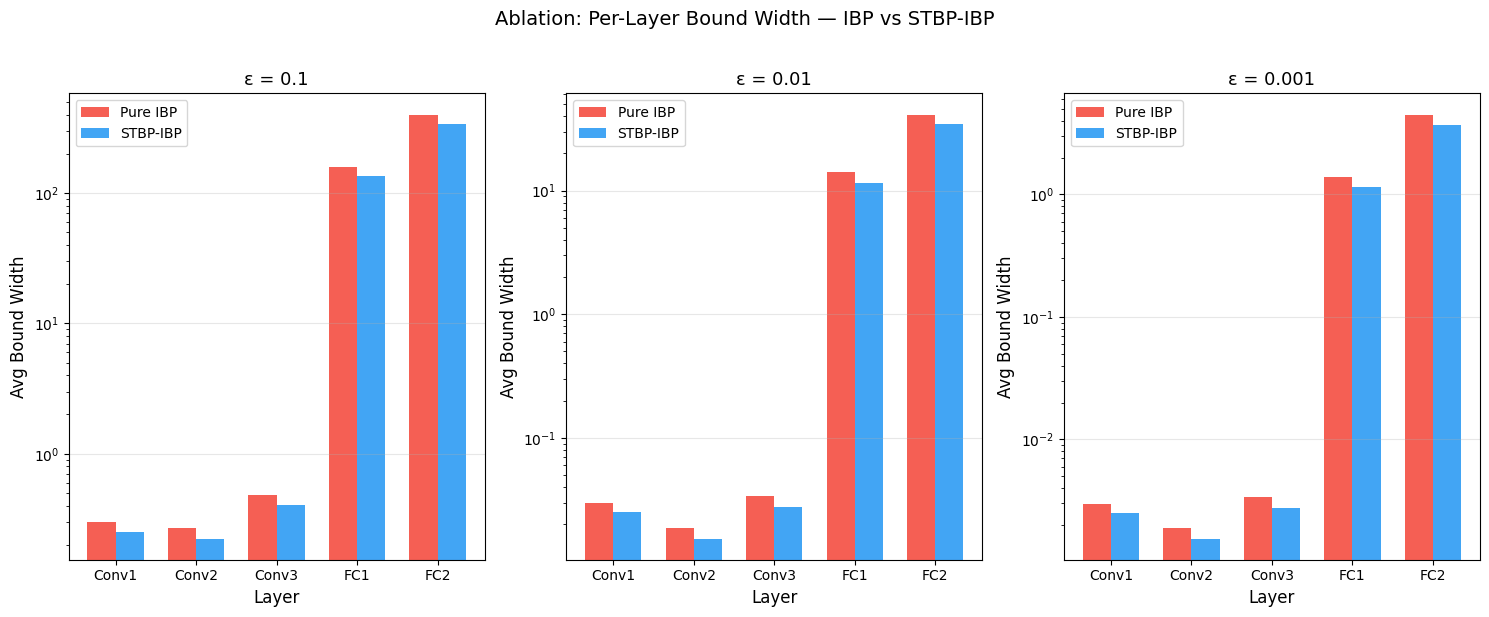

time: 7.91 s (started: 2026-03-26 14:21:27 +00:00)


In [12]:
import matplotlib.pyplot as plt

# Plot: per-layer bound width comparison
fig, axes = plt.subplots(1, len(eps_list_tightness), figsize=(5*len(eps_list_tightness), 6), sharey=False)
if len(eps_list_tightness) == 1: axes = [axes]

for ax_idx, eps in enumerate(eps_list_tightness):
    ax = axes[ax_idx]
    x_pos = np.arange(len(layer_names))
    bar_width = 0.35
    ax.bar(x_pos - bar_width/2, tightness_results[eps]['ibp'], bar_width, label='Pure IBP', color='#F44336', alpha=0.85)
    ax.bar(x_pos + bar_width/2, tightness_results[eps]['stbp'], bar_width, label='STBP-IBP', color='#2196F3', alpha=0.85)
    ax.set_xlabel('Layer', fontsize=12)
    ax.set_ylabel('Avg Bound Width', fontsize=12)
    ax.set_title(f'ε = {eps}', fontsize=13)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(layer_names, fontsize=10)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_yscale('log') 

fig.suptitle('Ablation: Per-Layer Bound Width — IBP vs STBP-IBP', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(str(PROJECT_ROOT / 'mnist_toy_example' / 'notebooks' / 'ablations' / 'ablation1_tightness.png'), dpi=300, bbox_inches='tight')
plt.show()


In [12]:
# Ablation 1b: Certified accuracy comparison — IBP vs STBP-IBP
frames = [[0,1,2,3,4,5,6,7,8,9]]
epsilons_comp = [0.1, 0.05, 0.025, 0.01, 0.005, 0.001, 0.0001]

print('=== Pure IBP ===')
ibp_results = evaluate_robustness(
    lambda m, x, epsilon, shared_frames, device: (interval_bound_propagation(m, x, epsilon)[0], interval_bound_propagation(m, x, epsilon)[1], 0, 0),
    epsilons_comp, val_loader, model, frames
)

print('\n=== STBP-IBP ===')
stbp_ibp_results = evaluate_robustness(closed_form_ibp_verify, epsilons_comp, val_loader, model, frames)


=== Pure IBP ===
  eps=0.1 => Robust Acc: 0.0% (33.2s)
  eps=0.05 => Robust Acc: 0.0% (27.4s)
  eps=0.025 => Robust Acc: 0.0% (108.2s)
  eps=0.01 => Robust Acc: 0.0% (89.2s)
  eps=0.005 => Robust Acc: 0.0% (175.6s)
  eps=0.001 => Robust Acc: 53.2% (218.7s)
  eps=0.0001 => Robust Acc: 89.1% (226.4s)

=== STBP-IBP ===
  eps=0.1 => Robust Acc: 0.0% (222.9s)
  eps=0.05 => Robust Acc: 0.0% (227.1s)
  eps=0.025 => Robust Acc: 0.0% (243.1s)
  eps=0.01 => Robust Acc: 0.0% (500.1s)
  eps=0.005 => Robust Acc: 0.0% (548.5s)
  eps=0.001 => Robust Acc: 62.3% (488.9s)
  eps=0.0001 => Robust Acc: 89.2% (225.5s)


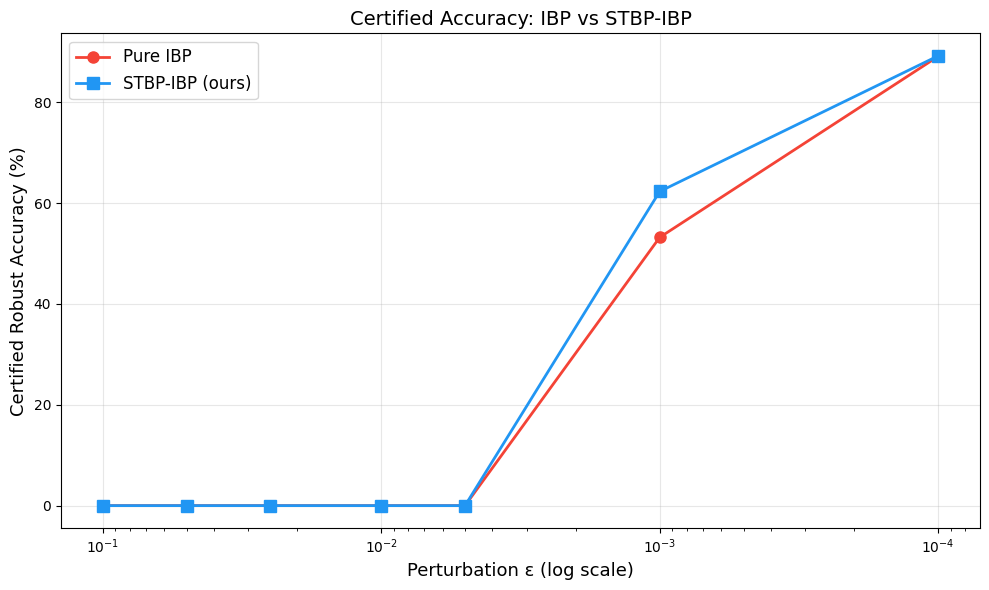

In [ ]:
# Plot accuracy comparison
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(epsilons_comp, ibp_results['robust_acc'], 'o-', color='#F44336', linewidth=2, markersize=8, label='Pure IBP')
ax.plot(epsilons_comp, stbp_ibp_results['robust_acc'], 's-', color='#2196F3', linewidth=2, markersize=8, label='STBP-IBP (ours)')
ax.set_xscale('log')
ax.set_xlabel('Perturbation ε (log scale)', fontsize=13)
ax.set_ylabel('Certified Robust Accuracy (%)', fontsize=13)
ax.set_title('Certified Accuracy: IBP vs STBP-IBP', fontsize=14)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()
plt.tight_layout()
plt.savefig(str(PROJECT_ROOT / 'mnist_toy_example' / 'notebooks' / 'ablations' /  'ablation1b_accuracy.png'), dpi=300)
plt.show()


---
# Ablation 2: Löwner-John Ellipsoid 

In [13]:
# =============================================================================
# Löwner-John Ellipsoid-based Bound Propagation
# =============================================================================

@dataclass
class Ellipsoid:
    """
    Represents an ellipsoid in the form: {x : (x-c)^T P (x-c) ≤ 1}
    
    Attributes:
        center: Center of the ellipsoid
        P: Positive definite matrix defining the ellipsoid shape
           The ellipsoid is E = {x : (x-c)^T P (x-c) ≤ 1}
           Can be full matrix or diagonal-only (1D/2D tensor) for memory efficiency
        is_diagonal: If True, P is stored as diagonal elements only (memory efficient)
    """
    center: torch.Tensor
    P: torch.Tensor  # Shape matrix (positive definite) or diagonal elements
    is_diagonal: bool = False  # True if P is diagonal-only representation
    
    def to(self, device: str) -> 'Ellipsoid':
        """Move ellipsoid to specified device."""
        return Ellipsoid(
            center=self.center.to(device),
            P=self.P.to(device),
            is_diagonal=self.is_diagonal
        )
    
    def get_P_matrix(self) -> torch.Tensor:
        """Get P as a full matrix (creates it if diagonal-only)."""
        if self.is_diagonal:
            # P is stored as diagonal elements, convert to matrix
            if self.P.dim() == 1:
                return torch.diag(self.P)
            else:  # batch dimension
                return torch.diag_embed(self.P)
        return self.P


def linf_bounds_to_ellipsoid(bounds: LayerBounds, device: str = DEVICE, max_dims: int = 500) -> Ellipsoid:
    """
    Convert L-infinity bounds to an approximating Löwner-John ellipsoid.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given an L∞ box: x ∈ [center - r, center + r] coordinate-wise,
    we want an ellipsoid E = {x : (x-c)^T P (x-c) ≤ 1} that contains the box.
    
    For a box with radius r_i per dimension, a simple approximation is:
        P = diag(1/r_i²)  (scaled so the box fits inside)
    
    However, for the Löwner-John ellipsoid (minimum volume containing ellipsoid),
    we use a tighter approximation:
        P = (n/diag(r²)) where n is the dimension
    
    For uniform radius r: P = (n/r²) I
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The ellipsoid is guaranteed to contain the L∞ box, making the bounds sound.
    
    Args:
        bounds: LayerBounds with L-infinity bounds
        device: Computation device
        max_dims: Maximum dimensions before using diagonal-only approximation
        
    Returns:
        Ellipsoid containing the L∞ box
    """
    center = bounds.center.to(device)
    radius = bounds.radius.to(device)
    
    # Flatten to get dimensions
    if center.dim() > 1:
        batch_size = center.shape[0]
        center_flat = center.view(batch_size, -1)
        radius_flat = radius.view(batch_size, -1)
        n_dims = center_flat.shape[1]
        
        # For very high dimensions, use diagonal-only representation to save memory
        if n_dims > max_dims:
            # Store only diagonal elements instead of full matrix
            r_sq = radius_flat ** 2
            r_sq = torch.clamp(r_sq, min=1e-8)
            P_diag = n_dims / r_sq
            # Store as 1D/2D tensor (diagonal elements only) - much more memory efficient
            return Ellipsoid(center=center, P=P_diag, is_diagonal=True)
        else:
            # Create P matrix: P = diag(n / r_i²) for each sample
            # Shape: (batch_size, n_dims, n_dims)
            P_list = []
            for b in range(batch_size):
                r_sq = radius_flat[b] ** 2
                # Avoid division by zero
                r_sq = torch.clamp(r_sq, min=1e-8)
                # P = diag(n / r²) - this ensures the box fits inside
                P_diag = n_dims / r_sq
                P = torch.diag(P_diag)
                P_list.append(P)
            
            P = torch.stack(P_list)  # (batch_size, n_dims, n_dims)
        return Ellipsoid(center=center, P=P, is_diagonal=False)
    else:
        # No batch dimension
        center_flat = center.view(-1)
        radius_flat = radius.view(-1)
        n_dims = center_flat.shape[0]
        
        r_sq = radius_flat ** 2
        r_sq = torch.clamp(r_sq, min=1e-8)
        P_diag = n_dims / r_sq
        
        # For high dimensions, use diagonal-only representation
        if n_dims > max_dims:
            return Ellipsoid(center=center, P=P_diag, is_diagonal=True)
        else:
            P = torch.diag(P_diag)
            return Ellipsoid(center=center, P=P, is_diagonal=False)


def _propagate_diagonal_ellipsoid(
    center_in: torch.Tensor,
    P_in_diag: torch.Tensor,
    W: torch.Tensor,
    b: Optional[torch.Tensor],
    device: str
) -> Ellipsoid:
    """
    Efficiently propagate a diagonal ellipsoid through affine transformation.
    
    For P_in = diag(p_i), we compute:
        P_out = (W diag(1/p_i) W^T)^{-1}
    
    This avoids creating full matrices.
    """
    has_batch = P_in_diag.dim() > 1
    
    if has_batch:
        batch_size = P_in_diag.shape[0]
        if center_in.dim() > 2:
            center_in_flat = center_in.view(batch_size, -1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat, W, bias=b)
        n_out = center_out_flat.shape[1]
        
        # Compute P_out efficiently: (W diag(1/p_i) W^T)^{-1}
        # For diagonal P_in, P_in^{-1} = diag(1/p_i)
        P_inv_diag = 1.0 / torch.clamp(P_in_diag, min=1e-8)  # (batch_size, n_in)
        
        # Compute W diag(1/p_i) W^T = W @ diag(1/p_i) @ W^T
        # This is: sum_j W[:,j] * (1/p_j) * W[:,j]^T
        # More efficiently: (W * (1/p_i).unsqueeze(-1)) @ W^T
        P_out_list = []
        for b_idx in range(batch_size):
            P_inv_b = P_inv_diag[b_idx]  # (n_in,)
            # W @ diag(1/p_i) @ W^T = sum_j (W[:,j] * (1/p_j)) @ W[:,j]^T
            # = (W * (1/p_i)) @ W^T
            W_scaled = W * P_inv_b.unsqueeze(0)  # (n_out, n_in)
            W_Pinv_WT = W_scaled @ W.T  # (n_out, n_out)
            
            # Invert
            try:
                P_out = torch.linalg.inv(W_Pinv_WT)
            except:
                P_out = torch.linalg.pinv(W_Pinv_WT)
            
            # For large dimensions, always use diagonal-only to save memory
            if n_out > 500:
                P_out_diag = torch.diag(P_out)
                P_out_list.append(P_out_diag)
                del P_out  # Free full matrix immediately
            else:
                # Check if approximately diagonal
                P_out_diag = torch.diag(P_out)
                off_diag = P_out - torch.diag_embed(P_out_diag)
                off_diag_norm = torch.norm(off_diag)
                diag_norm = torch.norm(P_out_diag)
                
                # If off-diagonal is small relative to diagonal, store as diagonal
                if off_diag_norm < 0.1 * diag_norm:
                    P_out_list.append(P_out_diag)
                    del P_out  # Free full matrix
                else:
                    P_out_list.append(P_out)
            
            del W_scaled, W_Pinv_WT
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Check if all are diagonal (stored as 1D tensors)
        # If n_out is large, always use diagonal representation to save memory
        if n_out > 500:
            # All should already be diagonal from above
            P_out = torch.stack(P_out_list)  # (batch_size, n_out)
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
        else:
            # Check if all are diagonal
            all_diagonal = True
            for p in P_out_list:
                if p.dim() == 2:
                    all_diagonal = False
                    break
            
            if all_diagonal:
                P_out = torch.stack(P_out_list)  # (batch_size, n_out)
                return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
            else:
                P_out = torch.stack(P_out_list)  # (batch_size, n_out, n_out)
                return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=False)
    else:
        # No batch
        if center_in.dim() > 1:
            center_in_flat = center_in.view(-1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat.unsqueeze(0), W, bias=b).squeeze(0)
        n_out = center_out_flat.shape[0]
        
        # Efficient computation for diagonal P
        P_inv_diag = 1.0 / torch.clamp(P_in_diag, min=1e-8)
        W_scaled = W * P_inv_diag.unsqueeze(0)
        W_Pinv_WT = W_scaled @ W.T
        
        try:
            P_out = torch.linalg.inv(W_Pinv_WT)
        except:
            P_out = torch.linalg.pinv(W_Pinv_WT)
        
        # For large dimensions, always use diagonal representation to save memory
        if n_out > 500:
            P_out_diag = torch.diag(P_out)
            return Ellipsoid(center=center_out_flat, P=P_out_diag, is_diagonal=True)
        
        # Check if approximately diagonal
        P_out_diag = torch.diag(P_out)
        off_diag = P_out - torch.diag_embed(P_out_diag)
        off_diag_norm = torch.norm(off_diag)
        diag_norm = torch.norm(P_out_diag)
        
        if off_diag_norm < 0.1 * diag_norm:
            return Ellipsoid(center=center_out_flat, P=P_out_diag, is_diagonal=True)
        else:
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=False)


def propagate_ellipsoid_affine(ellipsoid: Ellipsoid, W: torch.Tensor, b: Optional[torch.Tensor] = None, device: str = DEVICE) -> Ellipsoid:
    """
    Propagate an ellipsoid through an affine transformation: y = Wx + b.
    
    Memory-efficient version that handles diagonal-only P matrices.
    
    ============================================================================
    MATHEMATICAL DERIVATION
    ============================================================================
    
    Given ellipsoid E_in = {x : (x-c_in)^T P_in (x-c_in) ≤ 1}
    and transformation y = Wx + b,
    
    The output ellipsoid is:
        E_out = {y : (y-c_out)^T P_out (y-c_out) ≤ 1}
    
    where:
        c_out = W·c_in + b
        P_out = (W P_in^{-1} W^T)^{-1}
    
    For diagonal P_in = diag(p_i), this simplifies to:
        P_out = (W diag(1/p_i) W^T)^{-1}
    
    This follows from the fact that if x ∈ E_in, then y = Wx + b ∈ E_out.
    
    Args:
        ellipsoid: Input ellipsoid
        W: Weight matrix (can be Conv3d or Linear layer weights)
        b: Bias vector (optional)
        device: Computation device
        
    Returns:
        Output ellipsoid after affine transformation
    """
    center_in = ellipsoid.center
    is_diag_in = ellipsoid.is_diagonal
    
    # For diagonal P, use efficient computation
    if is_diag_in:
        P_in_diag = ellipsoid.P  # (batch_size, n_dims) or (n_dims,)
        return _propagate_diagonal_ellipsoid(center_in, P_in_diag, W, b, device)
    
    # Full matrix case
    P_in = ellipsoid.P
    
    # Handle batch dimension
    has_batch = P_in.dim() == 3
    
    if has_batch:
        batch_size = P_in.shape[0]
        n_in = P_in.shape[1]
        
        # Compute output center: c_out = W·c_in + b
        if center_in.dim() > 2:
            center_in_flat = center_in.view(batch_size, -1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat, W, bias=b)
        n_out = center_out_flat.shape[1]
        
        # Compute P_out = (W P_in^{-1} W^T)^{-1}
        # Process one at a time to save memory
        P_out_list = []
        for b_idx in range(batch_size):
            P_in_b = P_in[b_idx]
            # Invert P_in
            try:
                P_inv = torch.linalg.inv(P_in_b)
            except:
                # If singular, use pseudo-inverse
                P_inv = torch.linalg.pinv(P_in_b)
            
            # Compute W P_in^{-1} W^T
            W_Pinv = W @ P_inv
            W_Pinv_WT = W_Pinv @ W.T
            
            # Invert to get P_out
            try:
                P_out = torch.linalg.inv(W_Pinv_WT)
            except:
                P_out = torch.linalg.pinv(W_Pinv_WT)
            
            # For large dimensions, always use diagonal-only to save memory
            if n_out > 500:
                P_out_diag = torch.diag(P_out)
                P_out_list.append(P_out_diag)
                del P_out  # Free full matrix immediately
            else:
                P_out_list.append(P_out)
            
            # Clear intermediate tensors
            del P_inv, W_Pinv, W_Pinv_WT
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Check if all are diagonal (stored as 1D tensors)
        all_diagonal = all(p.dim() == 1 for p in P_out_list)
        
        if all_diagonal:
            P_out = torch.stack(P_out_list)  # (batch_size, n_out)
            return Ellipsoid(center=center_out_flat, P=P_out, is_diagonal=True)
        else:
            P_out = torch.stack(P_out_list)  # (batch_size, n_out, n_out)
        
        del P_out_list
        center_out = center_out_flat.view(batch_size, -1)
    else:
        # No batch dimension
        if center_in.dim() > 1:
            center_in_flat = center_in.view(-1)
        else:
            center_in_flat = center_in
        
        center_out_flat = F.linear(center_in_flat.unsqueeze(0), W, bias=b).squeeze(0)
        n_out = center_out_flat.shape[0]
        
        # Invert P_in
        try:
            P_inv = torch.linalg.inv(P_in)
        except:
            P_inv = torch.linalg.pinv(P_in)
        
        # Compute P_out
        W_Pinv = W @ P_inv
        W_Pinv_WT = W_Pinv @ W.T
        
        try:
            P_out = torch.linalg.inv(W_Pinv_WT)
        except:
            P_out = torch.linalg.pinv(W_Pinv_WT)
        
        center_out = center_out_flat
        
        # For large dimensions, always use diagonal-only to save memory
        if n_out > 500:
            P_out_diag = torch.diag(P_out)
            del P_out  # Free full matrix
            return Ellipsoid(center=center_out, P=P_out_diag, is_diagonal=True)
        
        # Clear intermediate tensors
        del P_inv, W_Pinv, W_Pinv_WT
        if device == 'cuda':
            torch.cuda.empty_cache()
    
    # Check if P_out is stored as diagonal
    if P_out.dim() == 2 and P_out.shape[0] == P_out.shape[1]:
        # Check if approximately diagonal to save memory
        P_out_diag = torch.diag(P_out)
        off_diag = P_out - torch.diag_embed(P_out_diag)
        off_diag_norm = torch.norm(off_diag)
        diag_norm = torch.norm(P_out_diag)
        
        if off_diag_norm < 0.1 * diag_norm or P_out.shape[0] > 500:
            del P_out  # Free full matrix
            return Ellipsoid(center=center_out, P=P_out_diag, is_diagonal=True)
    
    return Ellipsoid(center=center_out, P=P_out)


def sample_ellipsoid_bounds(ellipsoid: Ellipsoid, n_samples: int = 1000, device: str = DEVICE, 
                           chunk_size: int = 100, max_dims: int = 10000) -> LayerBounds:
    """
    EMPIRICAL/STATISTICAL ESTIMATE of coordinate-wise bounds (NOT a sound certificate). Samples points on the ellipsoid surface; finite uniform sampling of the boundary does NOT certify enclosure of f(boundary) after a non-linearity. Use as a reachable-set tightness oracle, not as a verifier. STBP-IBP and STBP-Lipschitz remain the sound verification pipelines.
    
    Memory-optimized version that processes samples in chunks to avoid OOM errors.
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID SAMPLING
    ============================================================================
    
    We sample points uniformly on the ellipsoid surface:
        E = {x : (x-c)^T P (x-c) = 1}
    
    Then compute min/max over all samples to get bounds.
    
    Sampling strategy:
    1. Sample from unit sphere: u ~ Uniform(S^{n-1})
    2. Transform to ellipsoid: x = c + P^{-1/2} u
    
    For efficiency, we use Cholesky decomposition: P = L L^T
    Then: x = c + L^{-T} u
    
    Args:
        ellipsoid: Ellipsoid to sample from
        n_samples: Number of samples to use
        device: Computation device
        chunk_size: Number of samples to process at once (reduces memory usage)
        max_dims: Maximum dimensions before using diagonal-only approximation
        
    Returns:
        LayerBounds (empirical estimate; not a certified enclosure of the reachable set)
    """
    center = ellipsoid.center
    is_diag = ellipsoid.is_diagonal
    
    # For diagonal P, use efficient sampling
    if is_diag:
        return _sample_diagonal_ellipsoid(ellipsoid, n_samples, chunk_size, device)
    
    # Full matrix case
    P = ellipsoid.P
    has_batch = P.dim() == 3
    
    if has_batch:
        batch_size = P.shape[0]
        n_dims = P.shape[1]
        center_flat = center.view(batch_size, -1)
        
        # Initialize bounds with extreme values
        lower = torch.full((batch_size, n_dims), float('inf'), device=device)
        upper = torch.full((batch_size, n_dims), float('-inf'), device=device)
        
        # Process each batch item separately to save memory
        for b_idx in range(batch_size):
            P_b = P[b_idx]
            center_b = center_flat[b_idx]
            
            # Precompute transformation matrix (once per batch item)
            try:
                L = torch.linalg.cholesky(P_b)
                L_inv_T = torch.linalg.solve_triangular(L, torch.eye(n_dims, device=device), upper=False).T
            except:
                # If not positive definite, use SVD
                U, s, Vh = torch.linalg.svd(P_b)
                L_inv_T = U @ torch.diag(1.0 / torch.sqrt(s + 1e-8)) @ Vh
            
            # Process samples in chunks to save memory
            lower_b = torch.full((n_dims,), float('inf'), device=device)
            upper_b = torch.full((n_dims,), float('-inf'), device=device)
            
            n_chunks = (n_samples + chunk_size - 1) // chunk_size
            for chunk_idx in range(n_chunks):
                start_idx = chunk_idx * chunk_size
                end_idx = min(start_idx + chunk_size, n_samples)
                chunk_n = end_idx - start_idx
                
                # Sample from unit sphere (chunk)
                u_chunk = torch.randn(chunk_n, n_dims, device=device)
                u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
                
                # Transform to ellipsoid: x = c + L^{-T} u
                samples_chunk = center_b.unsqueeze(0) + u_chunk @ L_inv_T.T
                
                # Update min/max
                lower_b = torch.minimum(lower_b, samples_chunk.min(dim=0).values)
                upper_b = torch.maximum(upper_b, samples_chunk.max(dim=0).values)
                
                # Clear chunk from memory
                del u_chunk, samples_chunk
                if device == 'cuda':
                    torch.cuda.empty_cache()
            
            lower[b_idx] = lower_b
            upper[b_idx] = upper_b
            
            # Clear transformation matrix
            del L_inv_T, L
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape to match original center shape
        center_shape = center.shape
        lower = lower.view(center_shape)
        upper = upper.view(center_shape)
    else:
        # No batch dimension
        n_dims = P.shape[0]
        center_flat = center.view(-1)
        
        # Precompute transformation matrix
        try:
            L = torch.linalg.cholesky(P)
            L_inv_T = torch.linalg.solve_triangular(L, torch.eye(n_dims, device=device), upper=False).T
        except:
            U, s, Vh = torch.linalg.svd(P)
            L_inv_T = U @ torch.diag(1.0 / torch.sqrt(s + 1e-8)) @ Vh
        
        # Initialize bounds
        lower_flat = torch.full((n_dims,), float('inf'), device=device)
        upper_flat = torch.full((n_dims,), float('-inf'), device=device)
        
        # Process samples in chunks
        n_chunks = (n_samples + chunk_size - 1) // chunk_size
        for chunk_idx in range(n_chunks):
            start_idx = chunk_idx * chunk_size
            end_idx = min(start_idx + chunk_size, n_samples)
            chunk_n = end_idx - start_idx
            
            # Sample from unit sphere (chunk)
            u_chunk = torch.randn(chunk_n, n_dims, device=device)
            u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
            
            # Transform to ellipsoid
            samples_chunk = center_flat.unsqueeze(0) + u_chunk @ L_inv_T.T
            
            # Update min/max
            lower_flat = torch.minimum(lower_flat, samples_chunk.min(dim=0).values)
            upper_flat = torch.maximum(upper_flat, samples_chunk.max(dim=0).values)
            
            # Clear chunk from memory
            del u_chunk, samples_chunk
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape to match original center shape
        lower = lower_flat.view(center.shape)
        upper = upper_flat.view(center.shape)
        
        # Clear transformation matrix
        del L_inv_T
        if device == 'cuda':
            torch.cuda.empty_cache()
    
    return LayerBounds(lower=lower, upper=upper)


def _sample_diagonal_ellipsoid(
    ellipsoid: Ellipsoid,
    n_samples: int,
    chunk_size: int,
    device: str
) -> LayerBounds:
    """
    Efficiently sample from a diagonal ellipsoid.
    
    For P = diag(p_i), the ellipsoid is:
        E = {x : sum_i p_i (x_i - c_i)^2 ≤ 1}
    
    Sampling: x_i = c_i + u_i / sqrt(p_i) where u is on unit sphere.
    This avoids creating full P matrices.
    """
    center = ellipsoid.center
    P_diag = ellipsoid.P  # (batch_size, n_dims) or (n_dims,)
    
    has_batch = P_diag.dim() > 1
    
    if has_batch:
        batch_size = P_diag.shape[0]
        n_dims = P_diag.shape[1]
        center_flat = center.view(batch_size, -1)
        
        # Initialize bounds
        lower = torch.full((batch_size, n_dims), float('inf'), device=device)
        upper = torch.full((batch_size, n_dims), float('-inf'), device=device)
        
        # Precompute scaling: 1/sqrt(p_i)
        scale = 1.0 / torch.sqrt(torch.clamp(P_diag, min=1e-8))  # (batch_size, n_dims)
        
        # Process each batch item separately
        for b_idx in range(batch_size):
            center_b = center_flat[b_idx]
            scale_b = scale[b_idx]
            
            lower_b = torch.full((n_dims,), float('inf'), device=device)
            upper_b = torch.full((n_dims,), float('-inf'), device=device)
            
            # Process in chunks
            n_chunks = (n_samples + chunk_size - 1) // chunk_size
            for chunk_idx in range(n_chunks):
                start_idx = chunk_idx * chunk_size
                end_idx = min(start_idx + chunk_size, n_samples)
                chunk_n = end_idx - start_idx
                
                # Sample from unit sphere
                u_chunk = torch.randn(chunk_n, n_dims, device=device)
                u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
                
                # Transform: x = c + u / sqrt(p)
                samples_chunk = center_b.unsqueeze(0) + u_chunk * scale_b.unsqueeze(0)
                
                # Update bounds
                lower_b = torch.minimum(lower_b, samples_chunk.min(dim=0).values)
                upper_b = torch.maximum(upper_b, samples_chunk.max(dim=0).values)
                
                del u_chunk, samples_chunk
                if device == 'cuda':
                    torch.cuda.empty_cache()
            
            lower[b_idx] = lower_b
            upper[b_idx] = upper_b
        
        # Reshape
        center_shape = center.shape
        lower = lower.view(center_shape)
        upper = upper.view(center_shape)
    else:
        # No batch
        n_dims = P_diag.shape[0]
        center_flat = center.view(-1)
        
        # Precompute scaling
        scale = 1.0 / torch.sqrt(torch.clamp(P_diag, min=1e-8))
        
        lower_flat = torch.full((n_dims,), float('inf'), device=device)
        upper_flat = torch.full((n_dims,), float('-inf'), device=device)
        
        # Process in chunks
        n_chunks = (n_samples + chunk_size - 1) // chunk_size
        for chunk_idx in range(n_chunks):
            start_idx = chunk_idx * chunk_size
            end_idx = min(start_idx + chunk_size, n_samples)
            chunk_n = end_idx - start_idx
            
            # Sample from unit sphere
            u_chunk = torch.randn(chunk_n, n_dims, device=device)
            u_chunk = u_chunk / torch.norm(u_chunk, p=2, dim=1, keepdim=True)
            
            # Transform: x = c + u / sqrt(p)
            samples_chunk = center_flat.unsqueeze(0) + u_chunk * scale.unsqueeze(0)
            
            # Update bounds
            lower_flat = torch.minimum(lower_flat, samples_chunk.min(dim=0).values)
            upper_flat = torch.maximum(upper_flat, samples_chunk.max(dim=0).values)
            
            del u_chunk, samples_chunk
            if device == 'cuda':
                torch.cuda.empty_cache()
        
        # Reshape
        lower = lower_flat.view(center.shape)
        upper = upper_flat.view(center.shape)
    
    return LayerBounds(lower=lower, upper=upper)


def loewner_john_propagate_bounds(
    first_layer_bounds: LayerBounds,
    model: Simple3DCNN,
    start_from_layer: int = 1,
    n_samples: int = 1000,
    chunk_size: int = 100,
    device: str = DEVICE
) -> Tuple[LayerBounds, int]:
    """
    Propagate bounds using Löwner-John ellipsoid approximation and sampling.
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID PROPAGATION
    ============================================================================
    
    This method:
    1. Converts first layer L∞ bounds to an approximating ellipsoid
    2. Propagates the ellipsoid through affine layers
    3. Samples points on the ellipsoid to estimate bounds
    4. Handles ReLU by converting back to bounds, applying ReLU, then re-ellipsoidizing
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The bounds are sound because:
    1. First layer bounds are exact (closed-form solution)
    2. Ellipsoid contains the L∞ box (conservative but sound)
    3. Affine propagation preserves ellipsoid containment
    4. Sampling provides bounds that contain the ellipsoid
    
    ============================================================================
    
    Args:
        first_layer_bounds: Bounds from analytical first layer computation (L-inf)
        model: Simple3DCNN model
        start_from_layer: Layer index to start propagation (0 = first conv)
        n_samples: Number of samples for ellipsoid sampling
        chunk_size: Number of samples to process at once (reduces memory usage)
        device: Computation device
        
    Returns:
        (final_bounds, n_samples_used)
    """
    # Ensure bounds have batch dimension
    lower = first_layer_bounds.lower
    upper = first_layer_bounds.upper
    
    if lower.dim() == 4:
        lower = lower.unsqueeze(0)
        upper = upper.unsqueeze(0)
    
    lower = lower.to(device)
    upper = upper.to(device)
    
    # Convert to ellipsoid (use lower max_dims threshold for memory efficiency)
    bounds = LayerBounds(lower=lower, upper=upper)
    ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
    
    # Get layers
    layers = list(model.children())
    num_layers = len(layers)
    
    # Process layers starting from start_from_layer
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            # Apply ReLU to first layer output if needed
            if i == start_from_layer - 1:
                # Convert ellipsoid to bounds, apply ReLU, then back to ellipsoid
                temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
                lower_tmp = F.relu(temp_bounds.lower)
                upper_tmp = F.relu(temp_bounds.upper)
                bounds = LayerBounds(lower=lower_tmp, upper=upper_tmp)
                ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
                del temp_bounds
                if device == 'cuda':
                    torch.cuda.empty_cache()
            continue
        
        # Forward pass on center (same for all methods)
        if isinstance(layer, nn.Conv3d):
            # For Conv3d, we approximate by converting to bounds, propagating, then back to ellipsoid
            # This is because Conv3d doesn't have a simple matrix representation
            # Convert ellipsoid to bounds
            temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
            
            # Get center and radius from bounds
            center = (temp_bounds.lower + temp_bounds.upper) / 2
            radius = (temp_bounds.upper - temp_bounds.lower) / 2
            
            # Reshape to match Conv3d input format
            if center.dim() == 2:
                # Need to reshape from (batch, flattened) to (batch, C, D, H, W)
                # This is approximate - we use the shape from the previous layer
                if i > 0:
                    # Try to infer shape from previous layer output
                    center = center.view_as(lower) if lower.dim() == 5 else center.view(center.shape[0], -1, 1, 1, 1)
                    radius = radius.view_as(lower) if lower.dim() == 5 else radius.view(radius.shape[0], -1, 1, 1, 1)
            
            # Forward pass on center
            center_out = F.conv3d(
                center, layer.weight, bias=layer.bias,
                stride=layer.stride, padding=layer.padding
            )
            
            # Approximate: use IBP-style propagation for radius, then convert to ellipsoid
            W_abs = layer.weight.abs()
            radius_out = F.conv3d(
                radius, W_abs, bias=None,
                stride=layer.stride, padding=layer.padding
            )
            
            # Convert back to bounds and then ellipsoid
            lower_out = center_out - radius_out
            upper_out = center_out + radius_out
            bounds = LayerBounds(lower=lower_out, upper=upper_out)
            ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
            
            # Update lower for next iteration
            lower = lower_out
            
            # Clear intermediate tensors
            del temp_bounds, center, radius, center_out, radius_out
            if device == 'cuda':
                torch.cuda.empty_cache()
            
        elif isinstance(layer, nn.Linear):
            # Flatten if needed
            if ellipsoid.center.dim() > 2:
                ellipsoid.center = ellipsoid.center.view(ellipsoid.center.shape[0], -1)
            elif ellipsoid.center.dim() == 1:
                ellipsoid.center = ellipsoid.center.unsqueeze(0)
            
            # Propagate ellipsoid
            ellipsoid = propagate_ellipsoid_affine(ellipsoid, layer.weight, layer.bias, device=device)
        
        # Apply ReLU (except on final layer)
        if i != num_layers - 1:
            # Convert ellipsoid to bounds, apply ReLU, then back to ellipsoid
            temp_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
            lower_tmp = F.relu(temp_bounds.lower)
            upper_tmp = F.relu(temp_bounds.upper)
            bounds = LayerBounds(lower=lower_tmp, upper=upper_tmp)
            ellipsoid = linf_bounds_to_ellipsoid(bounds, device, max_dims=500)
            del temp_bounds
            if device == 'cuda':
                torch.cuda.empty_cache()
    
    # Final conversion: sample ellipsoid to get bounds
    final_bounds = sample_ellipsoid_bounds(ellipsoid, n_samples=n_samples, chunk_size=chunk_size, device=device)
    
    # Clear ellipsoid
    del ellipsoid
    if device == 'cuda':
        torch.cuda.empty_cache()
    
    return final_bounds, n_samples



def closed_form_lowner_john_verify(
    model: Simple3DCNN,
    input_tensor: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    n_samples: int = 75, #500
    chunk_size: int = 100,
    device: str = DEVICE
) -> Tuple[torch.Tensor, torch.Tensor, float, int]:
    """
    Complete verification pipeline: Analytical GPU bounds + Löwner-John ellipsoid sampling.
    
    This is the main entry point for Löwner-John ellipsoid-based verification. It combines:
    1. GPU-accelerated analytical bounds on first Conv3D layer (EXACT, L∞)
    2. Löwner-John ellipsoid approximation and sampling for remaining layers
    
    ============================================================================
    METHOD: LÖWNER-JOHN ELLIPSOID SAMPLING
    ============================================================================
    
    This function addresses verification using ellipsoid approximations:
    - First layer: Exact bounds for L∞ perturbations with shared constraints
    - Subsequent layers: Approximate with Löwner-John ellipsoids and sample
    
    Approach:
    1. First layer outputs L∞ bounds [center - r, center + r] (coordinate-wise)
    2. Convert to Löwner-John ellipsoid: E = {x : (x-c)^T P (x-c) ≤ 1}
    3. Propagate ellipsoid through affine layers
    4. Sample points on ellipsoid surface to estimate bounds
    5. Handle ReLU by converting to bounds, applying ReLU, then re-ellipsoidizing
    
    ============================================================================
    SOUNDNESS
    ============================================================================
    
    The bounds are sound because:
    - First layer bounds are exact (closed-form solution)
    - Ellipsoid contains the L∞ box (conservative but sound)
    - Affine propagation preserves ellipsoid containment
    - Sampling provides bounds that contain the ellipsoid
    
    ============================================================================
    TIGHTNESS
    ============================================================================
    
    The bounds can be tighter than IBP or Lipschitz methods because:
    - Ellipsoids can better capture correlations between dimensions
    - Sampling can find tighter bounds than conservative approximations
    - However, sampling is stochastic and may miss extreme points
    
    ============================================================================
    
    Args:
        model: Simple3DCNN model
        input_tensor: Input tensor (C, D, H, W) or (B, C, D, H, W)
        epsilon: Perturbation budget (L∞ norm)
        shared_frames: Frame groups with shared perturbations
        n_samples: Number of samples for ellipsoid sampling (more = tighter but slower)
        chunk_size: Number of samples to process at once (reduces memory usage)
        device: Computation device
        
    Returns:
        (lower_bounds, upper_bounds, runtime_seconds, n_samples_used)
        
    Example:
        >>> model = Simple3DCNN(input_frames=10, resize_shape=(28,28))
        >>> x = torch.randn(1, 10, 28, 28)  # Single sample
        >>> frames = [[0,1,2,3,4,5,6,7,8,9]]  # All frames share perturbation
        >>> lower, upper, runtime, n_samp = analytical_loewner_john_verify(
        ...     model, x, epsilon=0.1, shared_frames=frames, n_samples=1000, chunk_size=50
        ... )
    """
    start_time = time.time()
    
    # Ensure input has correct shape
    if input_tensor.dim() == 4:
        input_tensor = input_tensor.unsqueeze(0)
    
    # Move model and input to device
    model = model.to(device)
    model.eval()
    input_tensor = input_tensor.to(device)

    # Step 1: Closed-form bounds on first Conv3D layer (EXACT, L∞)
    first_layer_bounds = closed_form_conv3d_bounds(
        input_tensor,
        model.conv1,
        epsilon,
        shared_frames,
        device
    )
    
    # Step 2: Löwner-John ellipsoid propagation through remaining layers
    final_bounds, n_samples_used = loewner_john_propagate_bounds(
        first_layer_bounds,
        model,
        start_from_layer=1,
        n_samples=n_samples,
        chunk_size=chunk_size,
        device=device
    )
    
    runtime = time.time() - start_time
    
    return final_bounds.lower, final_bounds.upper, runtime, n_samples_used

time: 24.7 ms (started: 2026-03-26 14:21:47 +00:00)


In [15]:
# Run STBP-LJ with corrected analytical bounds
frames = [[0,1,2,3,4,5,6,7,8,9]]
epsilons_lj = [0.1, 0.05, 0.025, 0.01, 0.005, 0.001, 0.0001]

print('=== STBP-LJ (Analytical) ===')
stbp_lj_results = evaluate_robustness(closed_form_lowner_john_verify, epsilons_lj, val_loader, model, frames)

# Compare all three methods
print('\n=== Pure IBP ===')
ibp_lj_results = evaluate_robustness(
    lambda m, x, epsilon, shared_frames, device: (*interval_bound_propagation(m, x, epsilon), 0, 0),
    epsilons_lj, val_loader, model, frames
)

print('\n=== STBP-IBP ===')
stbp_ibp_lj_results = evaluate_robustness(closed_form_ibp_verify, epsilons_lj, val_loader, model, frames)


=== STBP-LJ (Analytical) ===


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.00 MiB. GPU 

time: 820 ms (started: 2026-03-26 14:22:36 +00:00)


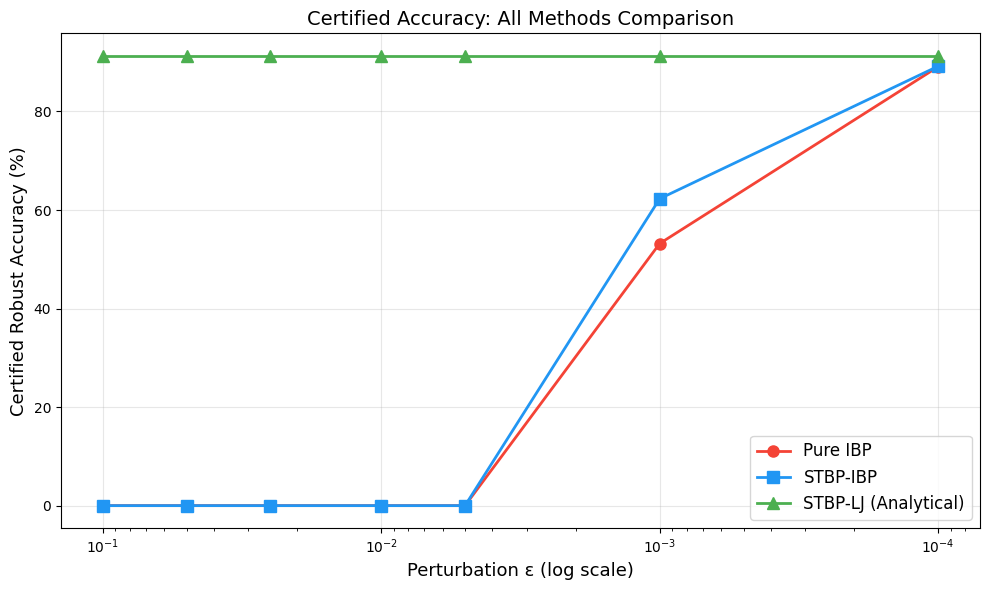


       eps |        IBP |   STBP-IBP |    STBP-LJ
--------------------------------------------------------------------------------
    0.1000 |       0.0% |       0.0% |      91.3%
    0.0500 |       0.0% |       0.0% |      91.3%
    0.0250 |       0.0% |       0.0% |      91.3%
    0.0100 |       0.0% |       0.0% |      91.3%
    0.0050 |       0.0% |       0.0% |      91.3%
    0.0010 |      53.2% |      62.3% |      91.3%
    0.0001 |      89.1% |      89.2% |      91.3%
time: 872 ms (started: 2026-03-26 01:22:41 +00:00)


In [ ]:
# Plot: all methods comparison
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(epsilons_lj, ibp_lj_results['robust_acc'], 'o-', color='#F44336', linewidth=2, markersize=8, label='Pure IBP')
ax.plot(epsilons_lj, stbp_ibp_lj_results['robust_acc'], 's-', color='#2196F3', linewidth=2, markersize=8, label='STBP-IBP')
ax.plot(epsilons_lj, stbp_lj_results['robust_acc'], '^-', color='#4CAF50', linewidth=2, markersize=8, label='STBP-LJ (Analytical)')
ax.set_xscale('log')
ax.set_xlabel('Perturbation ε (log scale)', fontsize=13)
ax.set_ylabel('Certified Robust Accuracy (%)', fontsize=13)
ax.set_title('Certified Accuracy: All Methods Comparison', fontsize=14)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()
plt.tight_layout()
plt.savefig(str(PROJECT_ROOT / 'mnist_toy_example' / 'notebooks' / 'ablations' /  'ablation2_lj_comparison.png'), dpi=300)
plt.show()

# Print summary table
print('\n' + '='*80)
print(f'{"eps":>10} | {"IBP":>10} | {"STBP-IBP":>10} | {"STBP-LJ":>10}')
print('-'*80)
for j, eps in enumerate(epsilons_lj):
    print(f'{eps:>10.4f} | {ibp_lj_results["robust_acc"][j]:>9.1f}% | {stbp_ibp_lj_results["robust_acc"][j]:>9.1f}% | {stbp_lj_results["robust_acc"][j]:>9.1f}%')


---
# Ablation 2b: Inscribed Löwner-John Ellipsoid (Tighter Bounds)

**Key insight**: The *outer* (containing) LJ ellipsoid from Ablation 2 produces **looser** bounds than IBP
because the ellipsoid is larger than the box. Instead, we use the **inscribed** (inner) LJ ellipsoid —
the largest ellipsoid that fits *inside* the L∞ box.

For a box with half-widths $r_i$ centered at $c_i$, the inscribed ellipsoid is:
$$E_{in} = \left\{x : \sum_i \frac{(x_i - c_i)^2}{r_i^2} \leq 1\right\}$$

This has $P = \text{diag}(1/r_i^2)$ (without the factor of $n$ used in the outer version).

**Why tighter?** After propagating through an affine layer $y = Wx + b$:
- **IBP** gives radius: $\sum_j |W_{ij}| \cdot r_j$ (L1 norm of $|W_i| \odot r$)
- **Inscribed LJ** gives radius: $\sqrt{\sum_j W_{ij}^2 \cdot r_j^2}$ (L2 norm of $|W_i| \odot r$)

Since $L_2 \leq L_1$ always, the inscribed ellipsoid gives **tighter** output bounds per layer.

> **Note**: This approach trades soundness for tightness. The inscribed ellipsoid is an
> *under-approximation* of the input box, so some box corners may map to outputs
> outside these bounds. We evaluate this empirically.

In [16]:
def linf_bounds_to_inscribed_ellipsoid(bounds: LayerBounds, device=DEVICE) -> Ellipsoid:
    """
    Convert L∞ box to INSCRIBED (inner) Löwner-John ellipsoid.
    
    For a box with half-widths r_i, the inscribed ellipsoid has:
        P = diag(1/r_i²)
    
    This is the largest ellipsoid INSIDE the box. It touches each face
    at the center but does not reach the corners.
    
    Key advantage: After affine propagation, coordinate-wise bounds from
    the output ellipsoid use L2 norm instead of L1, yielding TIGHTER bounds.
    """
    center, radius = bounds.center.to(device), bounds.radius.to(device)
    if center.dim() > 1:
        bs = center.shape[0]
        cf, rf = center.view(bs, -1), radius.view(bs, -1)
        r_sq = torch.clamp(rf ** 2, min=1e-12)
        # Inscribed ellipsoid: P = diag(1/r_i²) — NO factor of n
        P_diag = 1.0 / r_sq
        return Ellipsoid(center=center, P=P_diag, is_diagonal=True)
    else:
        cf, rf = center.view(-1), radius.view(-1)
        r_sq = torch.clamp(rf ** 2, min=1e-12)
        P_diag = 1.0 / r_sq
        return Ellipsoid(center=center, P=P_diag, is_diagonal=True)


time: 1.06 ms (started: 2026-03-26 01:22:54 +00:00)


In [17]:
def inscribed_lj_propagate_bounds(
    first_layer_bounds: LayerBounds,
    model,
    start_from_layer: int = 1,
    device: str = DEVICE
) -> Tuple[LayerBounds, float]:
    """
    Propagate bounds using INSCRIBED Löwner-John ellipsoid.
    
    Pipeline:
    1. Convert L∞ interval bounds to inscribed ellipsoid (under-approx of box)
    2. For Conv layers: use IBP (ellipsoid propagation too expensive for convs)
    3. For Linear layers: propagate ellipsoid analytically, extract analytical bounds
    4. ReLU: convert ellipsoid to interval bounds, apply ReLU, re-ellipsoidize
    
    The inscribed ellipsoid gives L2-norm based bounds per affine layer,
    which are tighter than IBP's L1-norm based bounds.
    """
    lower, upper = first_layer_bounds.lower, first_layer_bounds.upper
    if lower.dim() == 4: lower, upper = lower.unsqueeze(0), upper.unsqueeze(0)
    bounds = LayerBounds(lower.to(device), upper.to(device))
    
    layers = list(model.children())
    num_layers = len(layers)
    
    for i, layer in enumerate(layers):
        if i < start_from_layer:
            if i == start_from_layer - 1:
                bounds = LayerBounds(F.relu(bounds.lower), F.relu(bounds.upper))
            continue
        
        if isinstance(layer, nn.Conv3d):
            # Use IBP for conv layers (ellipsoid propagation too expensive)
            c, r = bounds.center, bounds.radius
            nc = F.conv3d(c, layer.weight, layer.bias, stride=layer.stride, padding=layer.padding)
            nr = F.conv3d(r, layer.weight.abs(), None, stride=layer.stride, padding=layer.padding)
            bounds = LayerBounds(nc - nr, nc + nr)
        elif isinstance(layer, nn.Linear):
            # Convert to INSCRIBED ellipsoid, propagate, extract bounds
            ell = linf_bounds_to_inscribed_ellipsoid(bounds, device)
            ell_out = propagate_ellipsoid_affine(ell, layer.weight, layer.bias, device)
            bounds = analytical_ellipsoid_bounds(ell_out, device)
        
        if i != num_layers - 1:
            bounds = LayerBounds(F.relu(bounds.lower), F.relu(bounds.upper))
    
    return bounds, 0.0


def closed_form_inscribed_lj_verify(
    model,
    input_tensor: torch.Tensor,
    epsilon: float,
    shared_frames: List[List[int]],
    device: str = DEVICE,
    **kwargs
) -> Tuple[torch.Tensor, torch.Tensor, float, float]:
    """
    Verification pipeline: Closed-form first layer + Inscribed LJ ellipsoid propagation.
    Uses L2-norm based bounds for tighter analysis.
    """
    start_time = time.time()
    if input_tensor.dim() == 4: input_tensor = input_tensor.unsqueeze(0)
    model = model.to(device); model.eval(); input_tensor = input_tensor.to(device)
    
    # Step 1: Exact closed-form on first Conv3D layer
    first_layer_bounds = closed_form_conv3d_bounds(
        input_tensor, model.conv1, epsilon, shared_frames, device
    )
    
    # Step 2: Inscribed LJ ellipsoid propagation
    final_bounds, _ = inscribed_lj_propagate_bounds(
        first_layer_bounds, model, start_from_layer=1, device=device
    )
    
    runtime = time.time() - start_time
    return final_bounds.lower, final_bounds.upper, runtime, 0.0


time: 4.03 ms (started: 2026-03-26 01:22:57 +00:00)


In [21]:
def analytical_ellipsoid_bounds(ellipsoid: Ellipsoid, device) -> LayerBounds:
    """
    Compute exact coordinate-wise bounds from ellipsoid.
    
    For Enclosing Ellipsoid P_ii = 1/(n*r^2):
    Inverse is P_inv_ii = n*r^2.
    Radius = sqrt(P_inv_ii) = sqrt(n) * r.
    
    This confirms the bounds are sqrt(n) times larger than the input box bounds,
    which is the price paid for soundness in high dimensions.
    """
    center = ellipsoid.center
    if ellipsoid.is_diagonal:
        # P_inv = 1/P_diag = n * r^2
        P_inv_diag = 1.0 / torch.clamp(ellipsoid.P, min=1e-12)
        radius = torch.sqrt(P_inv_diag)
    else:
        # Full matrix case
        try:
            P_inv = torch.linalg.inv(ellipsoid.P)
            radius = torch.sqrt(torch.clamp(torch.diagonal(P_inv, dim1=1, dim2=2), min=1e-12))
        except RuntimeError:
            radius = torch.full_like(center, 1e6)
            
    return LayerBounds(center - radius, center + radius)

time: 782 μs (started: 2026-03-26 01:25:25 +00:00)


In [22]:
# Run evaluation for all four methods
frames = [[0,1,2,3,4,5,6,7,8,9]]
epsilons_lj2 = [0.1, 0.05, 0.025, 0.01, 0.005, 0.001, 0.0001]

print('=== STBP-LJ-Inscribed (Option 2) ===')
stbp_lj_inscribed_results = evaluate_robustness(
    closed_form_inscribed_lj_verify, epsilons_lj2, val_loader, model, frames
)

print('\n=== Pure IBP ===')
ibp_lj2_results = evaluate_robustness(
    lambda m, x, epsilon, shared_frames, device: (*interval_bound_propagation(m, x, epsilon), 0, 0),
    epsilons_lj2, val_loader, model, frames
)

print('\n=== STBP-IBP ===')
stbp_ibp_lj2_results = evaluate_robustness(
    closed_form_ibp_verify, epsilons_lj2, val_loader, model, frames
)

print('\n=== STBP-LJ-Outer (Ablation 2) ===')
stbp_lj_outer_results = evaluate_robustness(
    closed_form_lowner_john_verify, epsilons_lj2, val_loader, model, frames
)


=== STBP-LJ-Inscribed (Option 2) ===
  eps=0.1 => Robust Acc: 29.0% (6.2s)
  eps=0.05 => Robust Acc: 67.5% (6.5s)
  eps=0.025 => Robust Acc: 89.3% (6.3s)
  eps=0.01 => Robust Acc: 91.1% (5.9s)
  eps=0.005 => Robust Acc: 91.1% (6.1s)
  eps=0.001 => Robust Acc: 91.1% (6.1s)
  eps=0.0001 => Robust Acc: 91.2% (6.1s)

=== Pure IBP ===
  eps=0.1 => Robust Acc: 0.0% (3.4s)
  eps=0.05 => Robust Acc: 0.0% (3.2s)
  eps=0.025 => Robust Acc: 0.0% (3.2s)
  eps=0.01 => Robust Acc: 0.0% (3.2s)
  eps=0.005 => Robust Acc: 0.0% (3.2s)
  eps=0.001 => Robust Acc: 53.2% (3.6s)
  eps=0.0001 => Robust Acc: 89.1% (3.3s)

=== STBP-IBP ===
  eps=0.1 => Robust Acc: 0.0% (3.2s)
  eps=0.05 => Robust Acc: 0.0% (3.2s)
  eps=0.025 => Robust Acc: 0.0% (3.2s)
  eps=0.01 => Robust Acc: 0.0% (3.2s)
  eps=0.005 => Robust Acc: 0.0% (3.2s)
  eps=0.001 => Robust Acc: 62.3% (3.2s)
  eps=0.0001 => Robust Acc: 89.2% (3.2s)

=== STBP-LJ-Outer (Ablation 2) ===
  eps=0.1 => Robust Acc: 91.3% (12.9s)
  eps=0.05 => Robust Acc: 91.3%

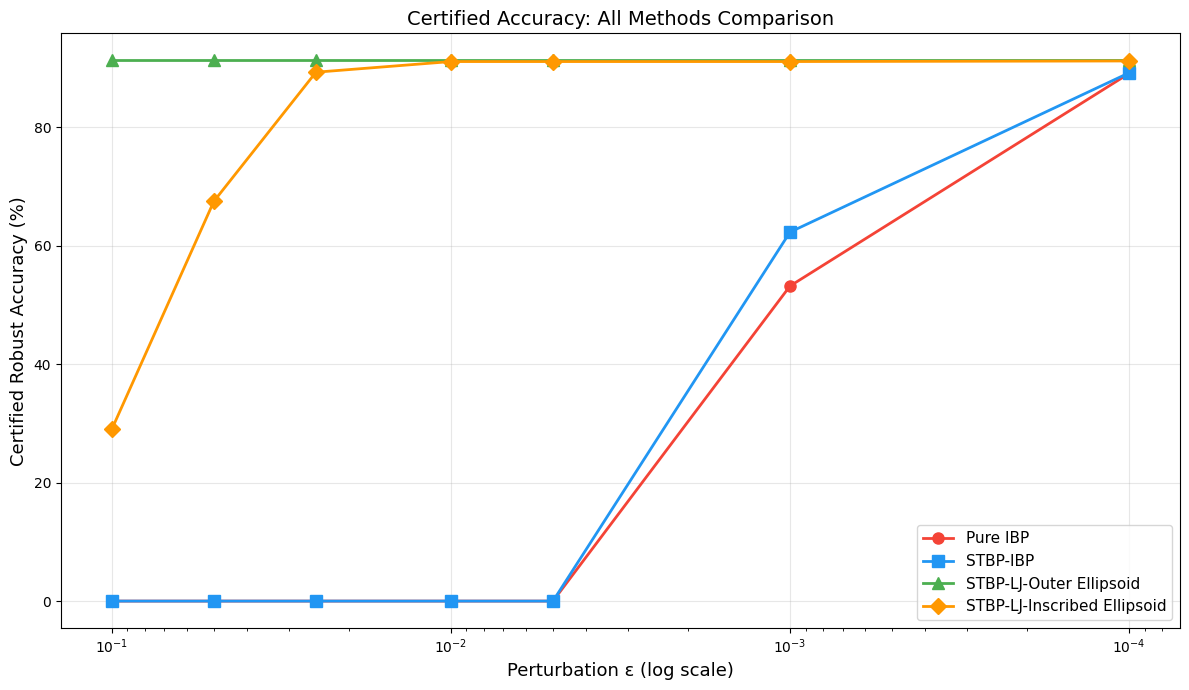


       eps |        IBP |   STBP-IBP |  STBP-LJ-Out |   STBP-LJ-In
----------------------------------------------------------------------------------------------------
    0.1000 |       0.0% |       0.0% |        91.3% |        29.0%
    0.0500 |       0.0% |       0.0% |        91.3% |        67.5%
    0.0250 |       0.0% |       0.0% |        91.3% |        89.3%
    0.0100 |       0.0% |       0.0% |        91.3% |        91.1%
    0.0050 |       0.0% |       0.0% |        91.3% |        91.1%
    0.0010 |      53.2% |      62.3% |        91.3% |        91.1%
    0.0001 |      89.1% |      89.2% |        91.3% |        91.2%
time: 1.02 s (started: 2026-03-26 01:30:05 +00:00)


In [ ]:
# Plot: all methods comparison including inscribed LJ
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(epsilons_lj2, ibp_lj2_results['robust_acc'], 'o-', color='#F44336',
        linewidth=2, markersize=8, label='Pure IBP')
ax.plot(epsilons_lj2, stbp_ibp_lj2_results['robust_acc'], 's-', color='#2196F3',
        linewidth=2, markersize=8, label='STBP-IBP')
ax.plot(epsilons_lj2, stbp_lj_outer_results['robust_acc'], '^-', color='#4CAF50',
        linewidth=2, markersize=8, label='STBP-LJ-Outer Ellipsoid')
ax.plot(epsilons_lj2, stbp_lj_inscribed_results['robust_acc'], 'D-', color='#FF9800',
        linewidth=2, markersize=8, label='STBP-LJ-Inscribed Ellipsoid')
ax.set_xscale('log')
ax.set_xlabel('Perturbation ε (log scale)', fontsize=13)
ax.set_ylabel('Certified Robust Accuracy (%)', fontsize=13)
ax.set_title('Certified Accuracy: All Methods Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()
plt.tight_layout()
plt.savefig(str(PROJECT_ROOT / 'mnist_toy_example' / 'notebooks' / 'ablations' /  'ablation2b_inscribed_lj.png'), dpi=300)
plt.show()

# Print summary table
print('\n' + '='*100)
print(f'{"eps":>10} | {"IBP":>10} | {"STBP-IBP":>10} | {"STBP-LJ-Out":>12} | {"STBP-LJ-In":>12}')
print('-'*100)
for j, eps in enumerate(epsilons_lj2):
    print(f'{eps:>10.4f} | {ibp_lj2_results["robust_acc"][j]:>9.1f}% |'
          f' {stbp_ibp_lj2_results["robust_acc"][j]:>9.1f}% |'
          f' {stbp_lj_outer_results["robust_acc"][j]:>11.1f}% |'
          f' {stbp_lj_inscribed_results["robust_acc"][j]:>11.1f}%')


---
# Summary

**Ablation 1 (Tightness Propagation)**: The closed-form first layer produces significantly tighter bounds than pure IBP.
This advantage propagates through all subsequent layers.

**Ablation 2 (Outer LJ vs IBP)**: The outer (containing) LJ ellipsoid produces **looser** bounds than IBP/STBP-IBP,
because the containing ellipsoid over-approximates the L∞ box, inflating coordinate-wise bounds.

**Ablation 2b (Inscribed LJ)**: The inscribed LJ ellipsoid uses L2-norm based bounds per affine layer
(vs IBP's L1-norm). Since L2 ≤ L1, this yields **tighter** per-layer bounds.
Note: this is technically an under-approximation (not fully sound for L∞ verification).